<a href="https://colab.research.google.com/github/SabaFeizi/Machine-Learning-Fall2026/blob/main/Data_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loading the Dataset and Initial Exploration

In this phase, we will load the dataset, take a quick look at the data, and understand the structure of the dataset by examining the columns, their data types, and the number of missing values for each feature. This initial exploration helps in identifying the types of features (numerical, categorical) and in planning how to handle any missing data.

In [ ]:

import pandas as pd

# Load the dataset
df = pd.read_csv("/Users/amiralighahramani/Desktop/Sharif University/4042/courses/2-Machine Learning/5-Jupyter Notebooks/1-Data Preprocessing/house-prices-advanced-regression-techniques/train.csv")


print("First 5 rows of the dataset:")
df.head(30)




First 5 rows of the dataset:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [ ]:
print(len(df))

1460


In [ ]:
# Display basic information about the dataset
print("\nDataset Information:")
df.info()




Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null  

In [ ]:
# Show the number of missing values for each column
print("\nNumber of missing values for each column:")
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print(missing_values)


Number of missing values for each column:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


# Handling Features with High Number of Missing Values



In practice, features with a high number of missing values can introduce noise or bias into the model, leading to unreliable predictions. Even if missing values can be handled using imputation techniques (e.g., filling with mean, median, mode, or more complex methods), the reliability of such imputed values decreases as the percentage of missing data increases.

A commonly used threshold to decide whether to drop a feature is if more than 50% of the data for that feature is missing. This threshold is somewhat arbitrary but widely accepted in practice because, beyond this point, the feature may not contribute meaningful information to the model. However, the exact threshold can vary depending on the specific dataset and domain knowledge.

In [ ]:
# Set the threshold for missing values. Common practice is 50%
threshold = 0.5 * len(df)

# Identify features to drop based on the threshold
features_to_drop = missing_values[missing_values > threshold].index

# Drop these features from the dataset
df_cleaned = df.drop(columns=features_to_drop)

# Display the names of the dropped features
print(f"Features dropped due to high number of missing values (>{threshold} missing values):")
print(list(features_to_drop))

# Display the shape of the dataset before and after dropping
print("\nOriginal dataset shape:", df.shape)
print("New dataset shape after dropping features:", df_cleaned.shape)


Features dropped due to high number of missing values (>730.0 missing values):
['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']

Original dataset shape: (1460, 81)
New dataset shape after dropping features: (1460, 76)


# Understanding Feature Types and Impuation Methods

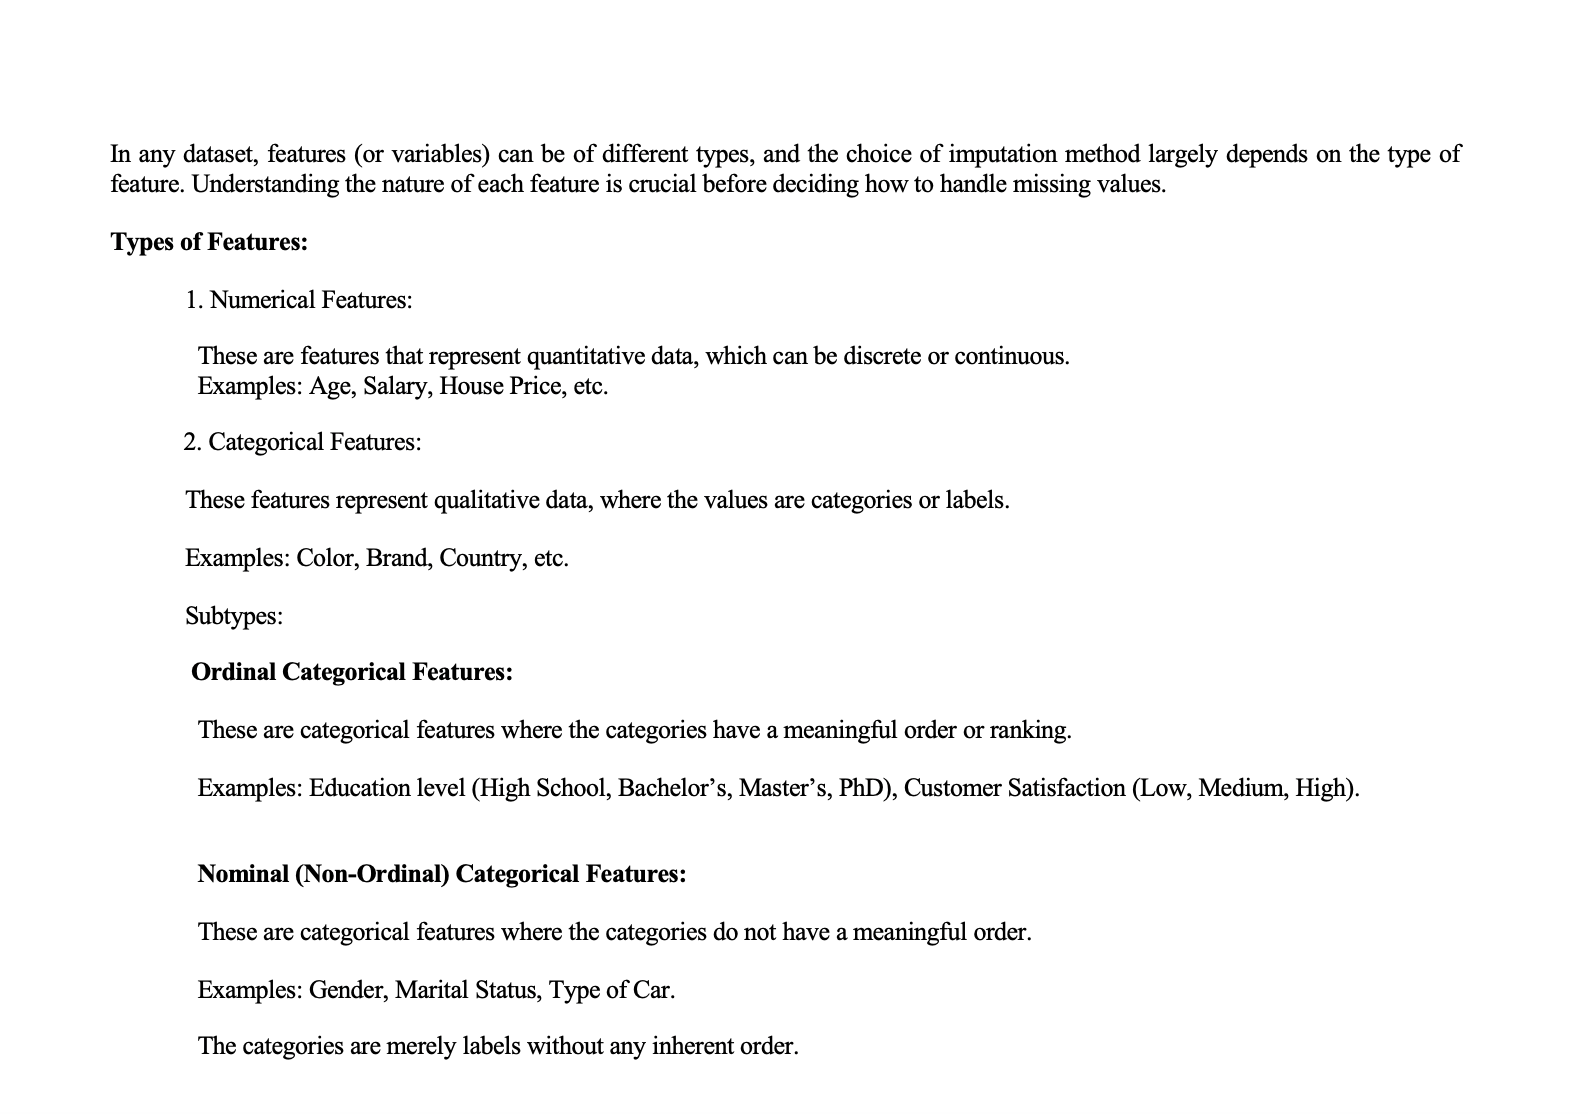
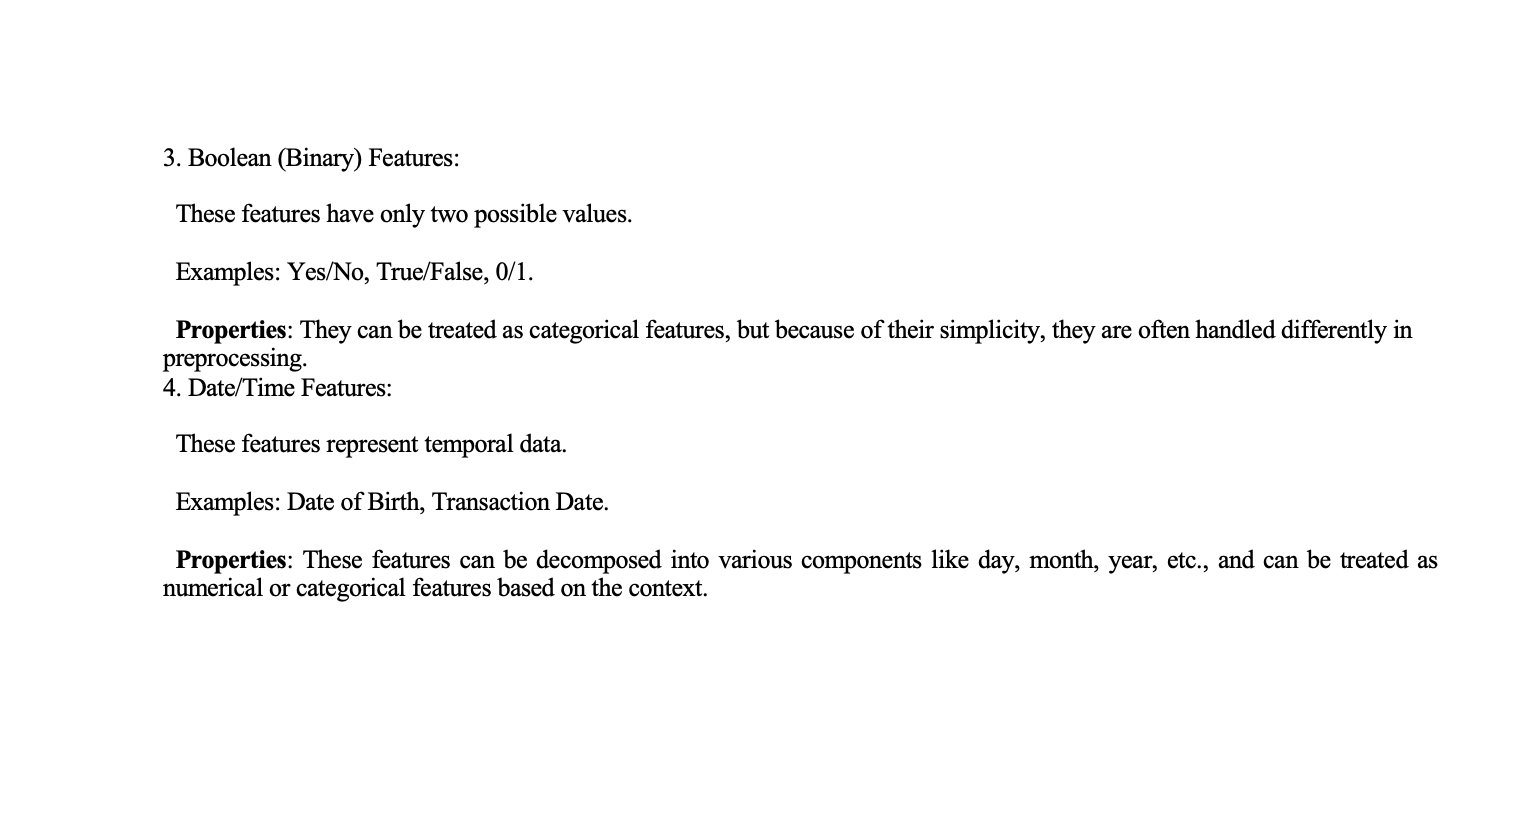

#Imputation Methods

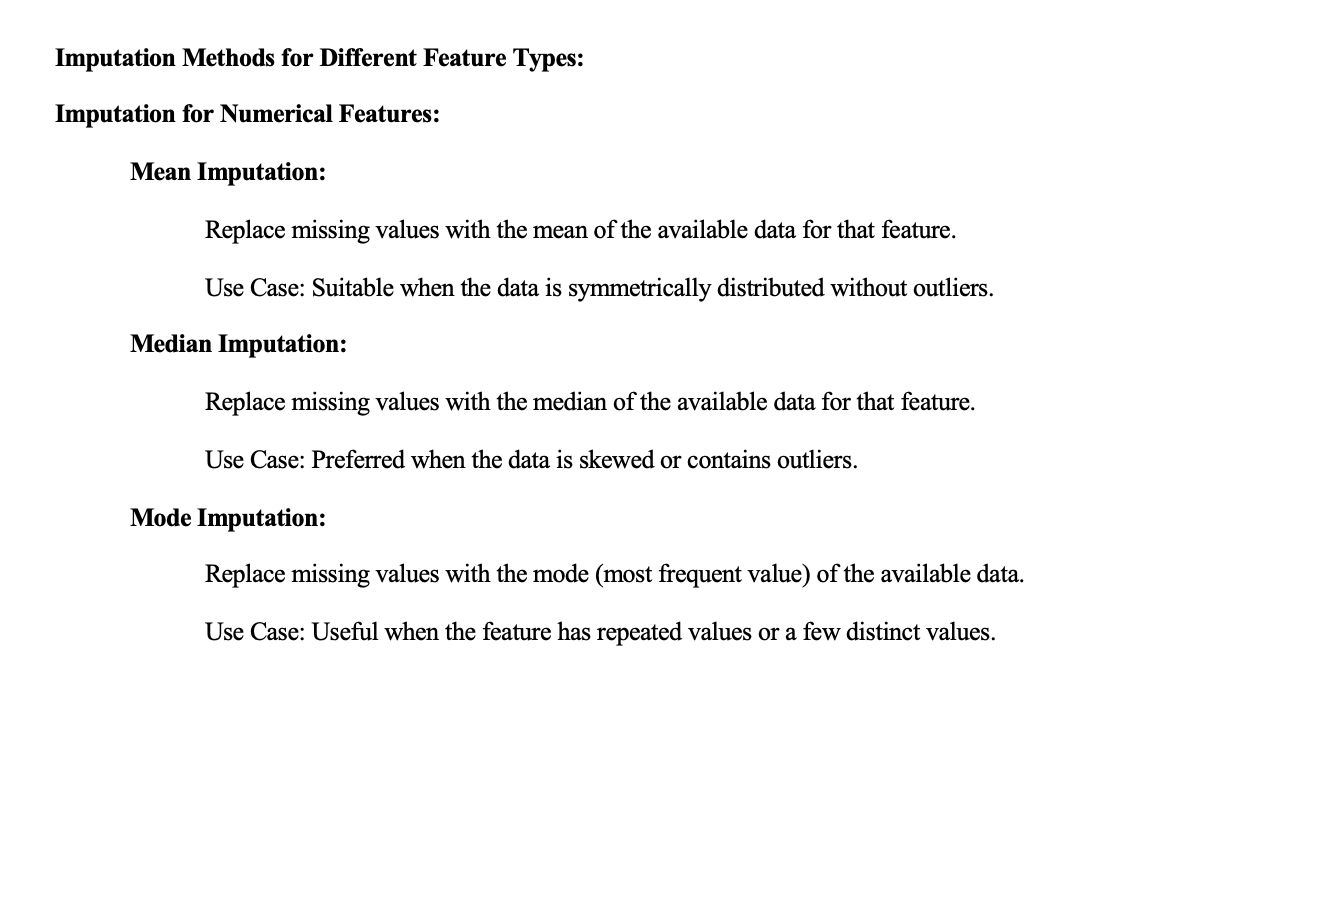

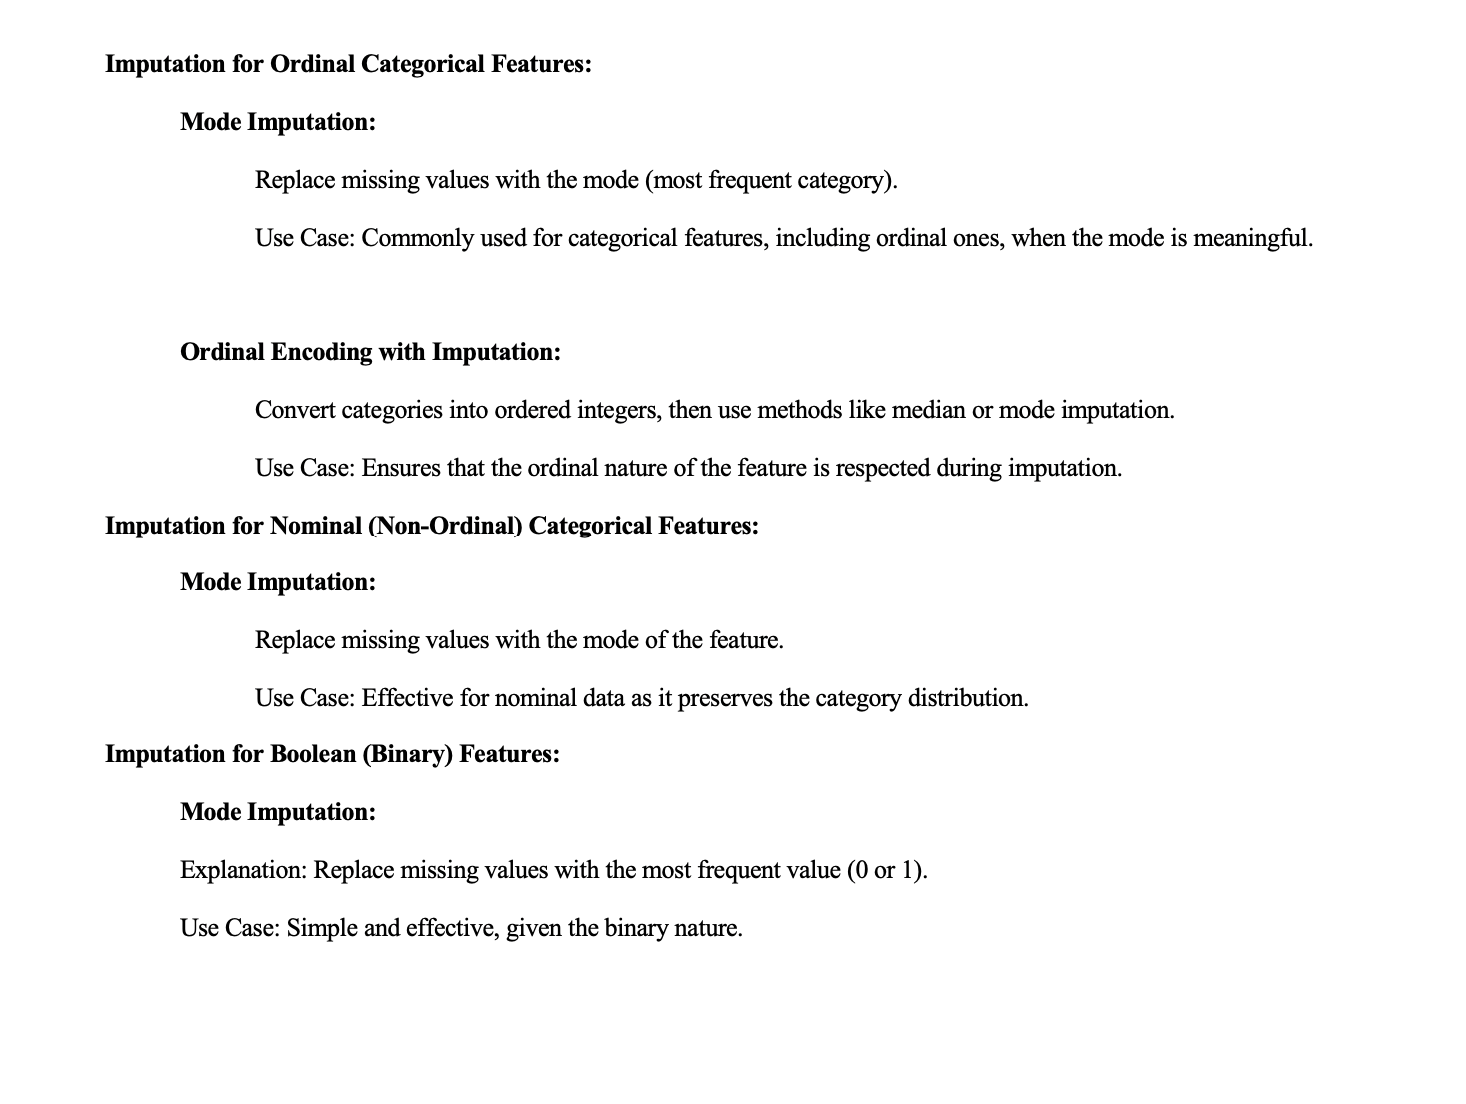

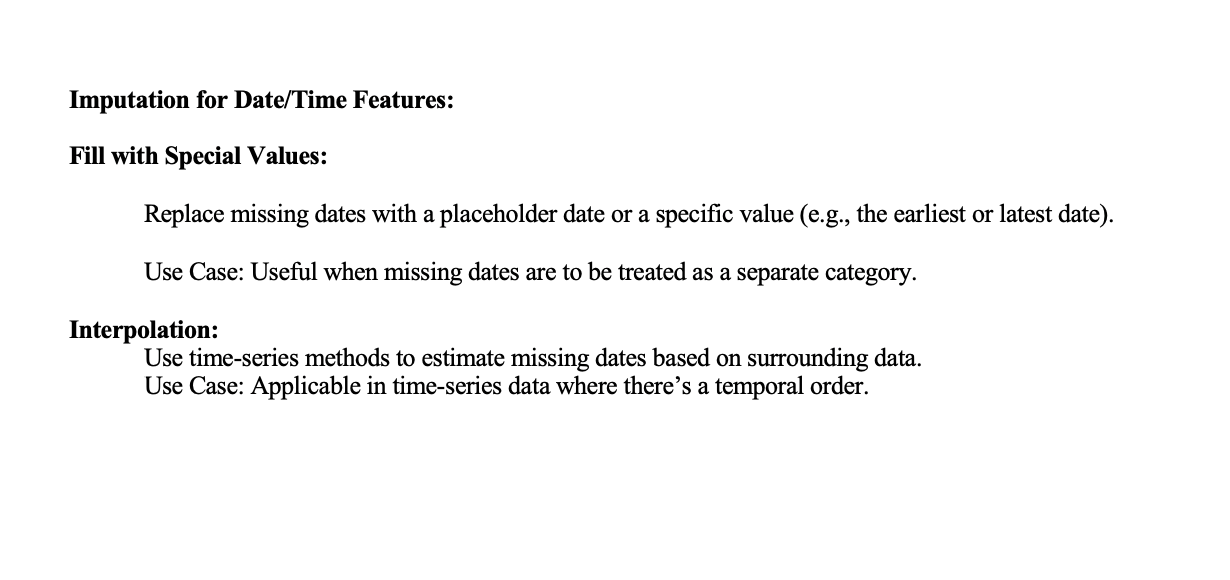

# Visualizing the Distribution of Numerical Features





Visualizing the distribution of numerical features is a crucial step in understanding the data. It helps to identify patterns, outliers, and the general shape of the data (e.g., whether it is normally distributed, skewed, etc.). This can guide further preprocessing steps, such as choosing appropriate imputation methods or deciding whether to apply transformations.

We'll use seaborn and matplotlib libraries to create a grid of histograms or density plots for each numerical feature in the dataset.

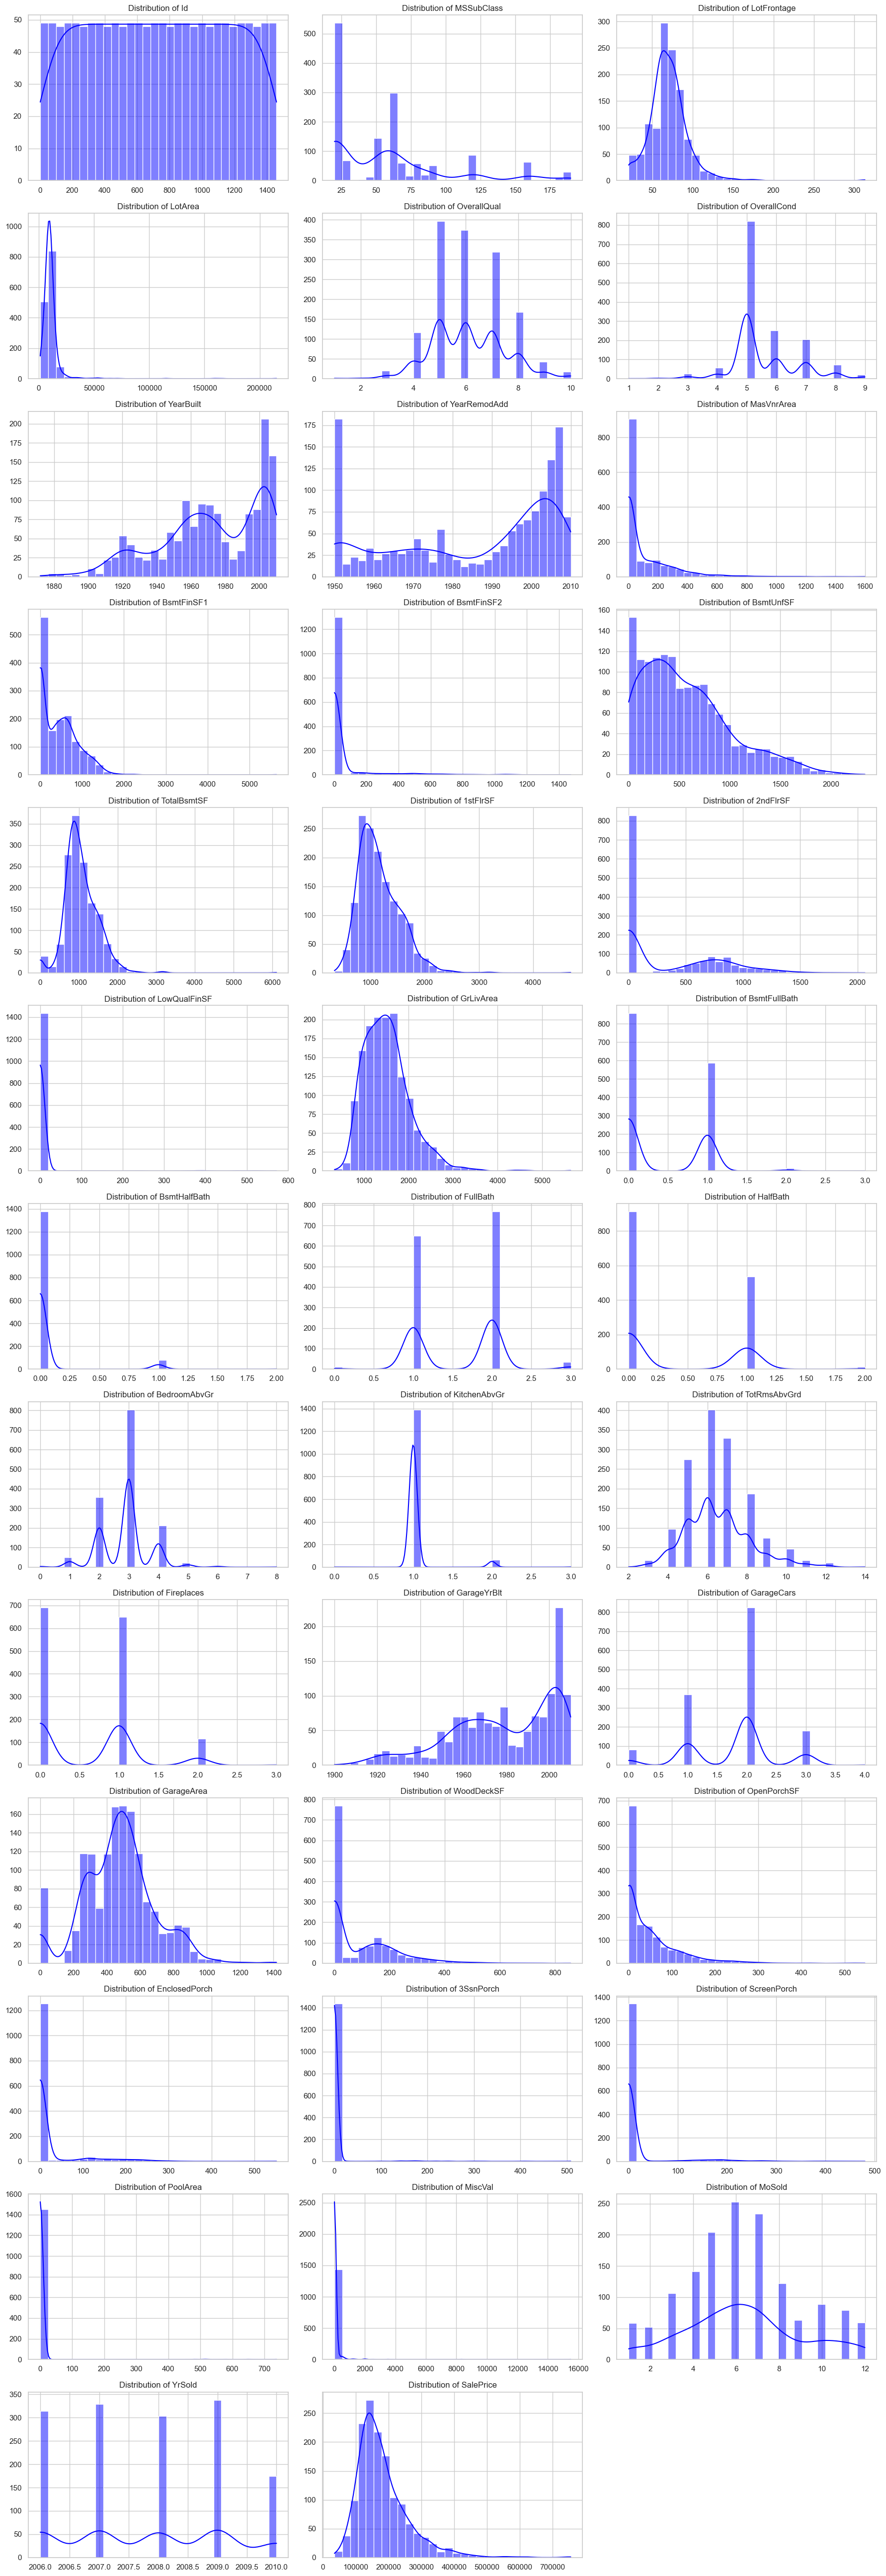

In [ ]:
# Import necessary libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for the plots
sns.set(style="whitegrid")

# Select only numerical features from the dataset
numerical_features = df_cleaned.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure and axes for a grid of plots
n_cols = 3  # Number of columns for the grid
n_rows = (len(numerical_features) + n_cols - 1) // n_cols  # Calculate the number of rows needed

# Create a figure with the appropriate size
plt.figure(figsize=(n_cols * 6, n_rows * 4))

# Loop over each numerical feature and create a subplot for its distribution
for i, feature in enumerate(numerical_features):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(df_cleaned[feature].dropna(), kde=True, bins=30, color='blue')  # Histogram with KDE
    plt.title(f'Distribution of {feature}')
    plt.xlabel('')
    plt.ylabel('')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()


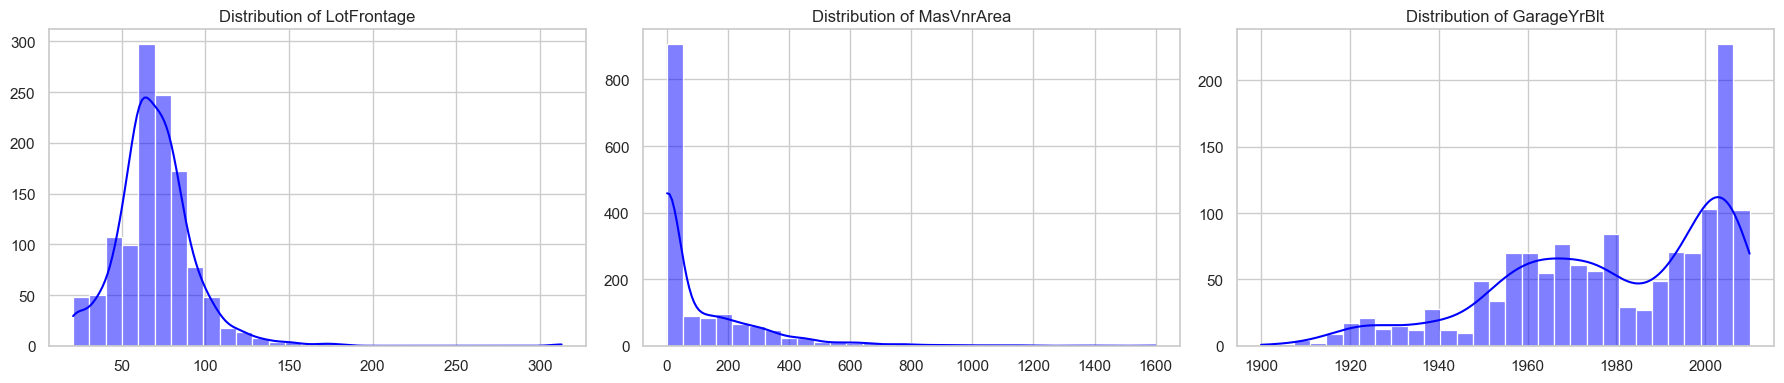

In [ ]:
# Select numerical features with missing values
numerical_with_missing = df_cleaned[numerical_features].columns[df_cleaned[numerical_features].isnull().sum() > 0]

# Set up the figure and axes for a grid of plots
n_cols = 3  # Number of columns for the grid
n_rows = (len(numerical_with_missing) + n_cols - 1) // n_cols  # Calculate the number of rows needed

# Create a figure with the appropriate size
plt.figure(figsize=(n_cols * 6, n_rows * 4))

# Loop over each numerical feature with missing values and create a subplot for its distribution
for i, feature in enumerate(numerical_with_missing):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(df_cleaned[feature].dropna(), kde=True, bins=30, color='blue')  # Histogram with KDE
    plt.title(f'Distribution of {feature}')
    plt.xlabel('')
    plt.ylabel('')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()





In [ ]:
# Print number of missing values for the selected features
for _, feature in enumerate(numerical_with_missing):
  print(f'{feature}:{df_cleaned[feature].isnull().sum()}\n')

LotFrontage:259

MasVnrArea:8

GarageYrBlt:81



# Imputation for Numerical Features

In this step, we will perform imputation for specific numerical features using different methods. We will impute missing values in the LotFrontage feature using the mean, while MasVnrArea and GarageYrBlt will be imputed using the median. These methods are chosen based on the distribution and characteristics of each feature.

In [ ]:
# Impute missing values for LotFrontage with the mean
mean_value = df_cleaned['LotFrontage'].mean()
df_cleaned['LotFrontage'].fillna(mean_value, inplace=True)

# Impute missing values for MasVnrArea with the median
median_value_masvnr = df_cleaned['MasVnrArea'].median()
df_cleaned['MasVnrArea'].fillna(median_value_masvnr, inplace=True)

# Impute missing values for GarageYrBlt with the median
median_value_garageyrblt = df_cleaned['GarageYrBlt'].median()
df_cleaned['GarageYrBlt'].fillna(median_value_garageyrblt, inplace=True)

# Display the number of missing values after imputation to verify
print("Number of missing values after imputation:")
print(df_cleaned[['LotFrontage', 'MasVnrArea', 'GarageYrBlt']].isnull().sum())


Number of missing values after imputation:
LotFrontage    0
MasVnrArea     0
GarageYrBlt    0
dtype: int64


/var/folders/hn/65j_14dx1tv2jy5frjhnj81w0000gn/T/ipykernel_8417/596420549.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_cleaned['LotFrontage'].fillna(mean_value, inplace=True)
/var/folders/hn/65j_14dx1tv2jy5frjhnj81w0000gn/T/ipykernel_8417/596420549.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting value

In [ ]:
# The same code, but this time with Scikitlearn
from sklearn.impute import SimpleImputer

# Impute missing values for LotFrontage with the mean
imputer_mean = SimpleImputer(strategy='mean')
df_cleaned['LotFrontage'] = imputer_mean.fit_transform(df_cleaned[['LotFrontage']])

# Impute missing values for MasVnrArea with the median
imputer_median_masvnr = SimpleImputer(strategy='median')
df_cleaned['MasVnrArea'] = imputer_median_masvnr.fit_transform(df_cleaned[['MasVnrArea']])

# Impute missing values for GarageYrBlt with the median
imputer_median_garageyrblt = SimpleImputer(strategy='median')
df_cleaned['GarageYrBlt'] = imputer_median_garageyrblt.fit_transform(df_cleaned[['GarageYrBlt']])

# Display the number of missing values after imputation to verify
print("Number of missing values after imputation:")
print(df_cleaned[['LotFrontage', 'MasVnrArea', 'GarageYrBlt']].isnull().sum())


Number of missing values after imputation:
LotFrontage    0
MasVnrArea     0
GarageYrBlt    0
dtype: int64


# Imputation for Categorical Features

Before handling missing values in categorical features, it's important to identify which categorical features have missing values and how many. This will help in deciding the appropriate imputation strategy, such as using the mode (most frequent value) or a placeholder value.

In [ ]:
# Select only categorical features from the dataset
categorical_features = df_cleaned.select_dtypes(include=['object']).columns

# Display the number of missing values for each categorical feature
missing_values_categorical = df_cleaned[categorical_features].isnull().sum()
missing_values_categorical = missing_values_categorical[missing_values_categorical > 0].sort_values(ascending=False)

# Print the categorical features with their number of missing values
print("Categorical features with missing values:")
print(missing_values_categorical)


Categorical features with missing values:
FireplaceQu     690
GarageQual       81
GarageFinish     81
GarageCond       81
GarageType       81
BsmtExposure     38
BsmtFinType2     38
BsmtCond         37
BsmtQual         37
BsmtFinType1     37
Electrical        1
dtype: int64


In [ ]:
#Now, let's see what are the unique values of these features!
# Loop through each categorical feature with missing values
for feature in missing_values_categorical.index:
    unique_values = df_cleaned[feature].unique()

    # Display the feature name and its unique values
    print(f"Feature: {feature}")
    print(f"Unique values: {unique_values}")
    print("-" * 50)


Feature: FireplaceQu
Unique values: [nan 'TA' 'Gd' 'Fa' 'Ex' 'Po']
--------------------------------------------------
Feature: GarageQual
Unique values: ['TA' 'Fa' 'Gd' nan 'Ex' 'Po']
--------------------------------------------------
Feature: GarageFinish
Unique values: ['RFn' 'Unf' 'Fin' nan]
--------------------------------------------------
Feature: GarageCond
Unique values: ['TA' 'Fa' nan 'Gd' 'Po' 'Ex']
--------------------------------------------------
Feature: GarageType
Unique values: ['Attchd' 'Detchd' 'BuiltIn' 'CarPort' nan 'Basment' '2Types']
--------------------------------------------------
Feature: BsmtExposure
Unique values: ['No' 'Gd' 'Mn' 'Av' nan]
--------------------------------------------------
Feature: BsmtFinType2
Unique values: ['Unf' 'BLQ' nan 'ALQ' 'Rec' 'LwQ' 'GLQ']
--------------------------------------------------
Feature: BsmtCond
Unique values: ['TA' 'Gd' nan 'Fa' 'Po']
--------------------------------------------------
Feature: BsmtQual
Unique values: 

In [ ]:
from sklearn.impute import SimpleImputer

# Select only categorical columns
categorical_features = df_cleaned.select_dtypes(include=['object'])

# Identify categorical features with missing values
categorical_features_with_na = categorical_features.columns[categorical_features.isnull().any()]

# Initialize the SimpleImputer with strategy='most_frequent' to replace missing values with the mode
imputer = SimpleImputer(strategy='most_frequent')

# Apply the imputer only to the categorical features with missing values
df_cleaned[categorical_features_with_na] = imputer.fit_transform(df_cleaned[categorical_features_with_na])

# Display the dataframe to verify the changes
print(df_cleaned[categorical_features_with_na].isnull().sum())


BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
Electrical      0
FireplaceQu     0
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
dtype: int64


In [ ]:
df_cleaned.isnull().sum()

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
                ..
MoSold           0
YrSold           0
SaleType         0
SaleCondition    0
SalePrice        0
Length: 76, dtype: int64

# Understanding the Correlation Between Numerical features and the Target Variable

Correlation is a statistical measure that describes the strength and direction of the relationship between two variables. In the context of a dataset, it tells us how one feature is related to another. When working with numerical features, understanding their correlation with the target variable (in this case, SalePrice) can provide insights into which features are most influential in predicting the target.

Positive Correlation: If a numerical feature increases as the SalePrice increases, the correlation is positive. For example, features like GrLivArea (above-ground living area) might have a strong positive correlation with SalePrice.

Negative Correlation: If a numerical feature decreases as the SalePrice increases, the correlation is negative. For example, a feature like OverallCond (overall condition) might negatively correlate if lower numbers represent better condition.

No Correlation: If the feature and SalePrice do not exhibit any relationship, the correlation will be close to 0.

The correlation coefficient value ranges from -1 to 1:

1 indicates a perfect positive correlation.
-1 indicates a perfect negative correlation.
0 indicates no correlation.


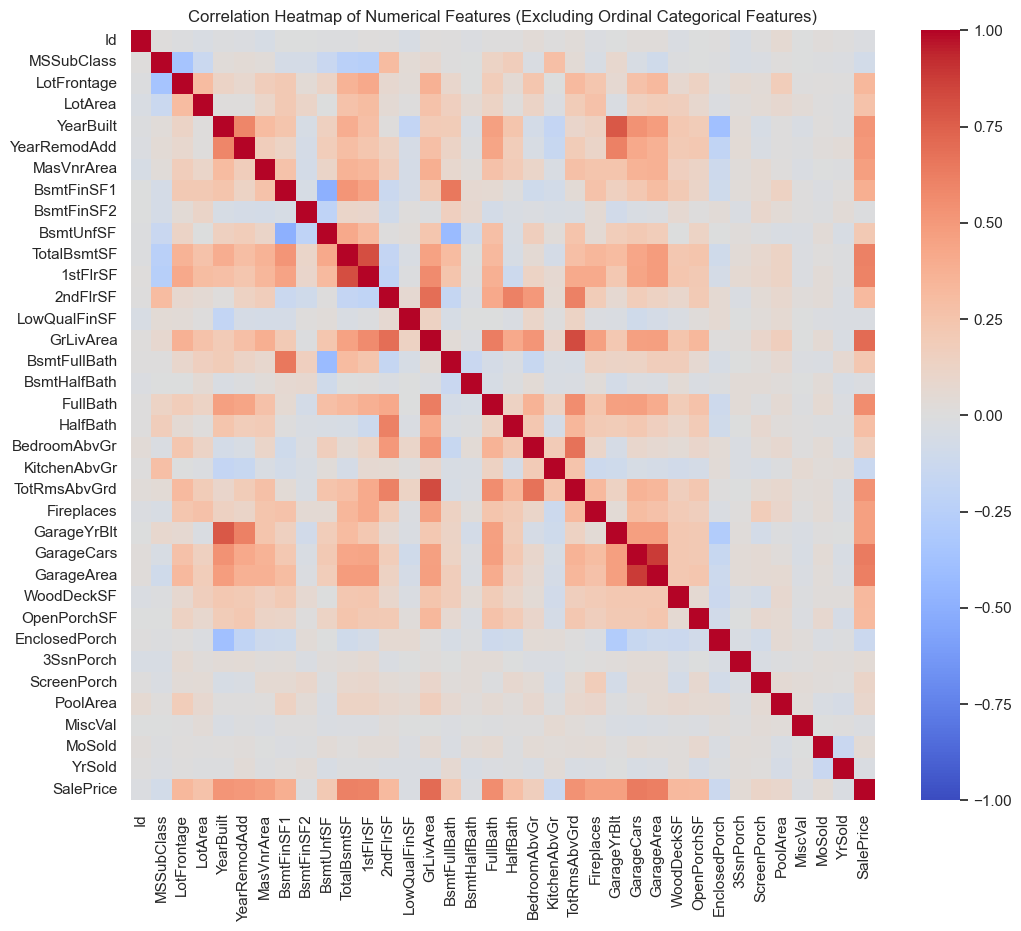

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# List of ordinal categorical features to exclude
# ordinal_features = ['OverallQual', 'OverallCond', 'MoSold', 'YrSold']
ordinal_features = ['OverallQual', 'OverallCond']

# Select only the numerical features excluding the ordinal ones
numerical_features = df_cleaned.select_dtypes(include=['float64', 'int64']).drop(columns=ordinal_features)

# Calculate the correlation matrix for numerical features
correlation_matrix = numerical_features.corr()

# Plotting the heatmap for the correlation between numerical features
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numerical Features (Excluding Ordinal Categorical Features)')
plt.show()



In [ ]:
# Extract the correlation of each numerical feature with SalePrice
correlation_with_target = correlation_matrix["SalePrice"].sort_values(ascending=False)

# Display the correlation values
print("Correlation of numerical features with SalePrice:\n", correlation_with_target)

Correlation of numerical features with SalePrice:
 SalePrice        1.000000
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
GarageYrBlt      0.466754
BsmtFinSF1       0.386420
LotFrontage      0.334901
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePri

In [ ]:

#keep features with high positive or negative correlation


def get_highly_correlated_features(correlation_with_target, threshold=0.3):



  highly_correlated_features = correlation_with_target[(correlation_with_target > threshold) | (correlation_with_target < -threshold)]
  return highly_correlated_features.index.tolist()



# Get highly correlated features with a threshold of 0.3
highly_correlated_numerical = get_highly_correlated_features(correlation_with_target)
print(highly_correlated_numerical)


['SalePrice', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'Fireplaces', 'GarageYrBlt', 'BsmtFinSF1', 'LotFrontage', 'WoodDeckSF', '2ndFlrSF', 'OpenPorchSF']


# Correlation Between Categorical Features and Target variable
One approach is to encode the categorical features to numeric values and use the correlation function. In this way, you have to take into account the characteristics of Ordinal and Non-ordinal features.

Another approach is to use some statistical tests that evaluate the dependence between the categorical feature and the target variable

To this aim, we can apply the ANOVA (Analysis of Variance) test. ANOVA tests whether there are any statistically significant differences between the means of the categories of the categorical feature in relation to the numerical target.

ANOVA test outputs two values: the F-value and the P-Value.
the F-value indicates the ratio of variance between the groups to the variance within the groups and a p-value indicates the significance of the result.

F-Value: Higher F-values indicate a stronger relationship between the categorical feature and the numerical target variable (SalePrice).
P-Value: A smaller p-value (typically < 0.05) suggests that the observed differences between groups are statistically significant.

In [ ]:
categorical_features = df_cleaned.select_dtypes(include=['object'])
for feature in categorical_features.columns:
  print(feature)


MSZoning
Street
LotShape
LandContour
Utilities
LotConfig
LandSlope
Neighborhood
Condition1
Condition2
BldgType
HouseStyle
RoofStyle
RoofMatl
Exterior1st
Exterior2nd
ExterQual
ExterCond
Foundation
BsmtQual
BsmtCond
BsmtExposure
BsmtFinType1
BsmtFinType2
Heating
HeatingQC
CentralAir
Electrical
KitchenQual
Functional
FireplaceQu
GarageType
GarageFinish
GarageQual
GarageCond
PavedDrive
SaleType
SaleCondition


In [ ]:
categorical_features_list = categorical_features.columns.tolist() + ordinal_features
categorical_features_list


['MSZoning',
 'Street',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'SaleType',
 'SaleCondition',
 'OverallQual',
 'OverallCond']

In [ ]:
from scipy.stats import f_oneway
import pandas as pd

# Prepare a list to store the results
anova_results = []

# Loop through each categorical feature
for feature in categorical_features_list:
    # Get the groups for each unique category within the feature
    groups = [df_cleaned['SalePrice'][df_cleaned[feature] == category].dropna() for category in df_cleaned[feature].unique()]

    # Perform one-way ANOVA
    f_value, p_value = f_oneway(*groups)

    # Append the results to the list
    anova_results.append({'Feature': feature, 'F-Value': f_value, 'P-Value': p_value})

# Convert the list to a DataFrame
anova_results_df = pd.DataFrame(anova_results)

# Sort the results by F-Value
anova_results_df = anova_results_df.sort_values(by='F-Value', ascending=False)

print(anova_results_df)


          Feature     F-Value        P-Value
16      ExterQual  443.334831  1.439551e-204
19       BsmtQual  413.945648  2.078120e-194
28    KitchenQual  407.806352  3.032213e-192
38    OverallQual  349.026840   0.000000e+00
32   GarageFinish  303.619407  5.993319e-111
18     Foundation  100.253851   5.791895e-91
26     CentralAir   98.305344   1.809506e-22
25      HeatingQC   88.394462   2.667062e-67
21   BsmtExposure   76.577934   5.394238e-46
7    Neighborhood   71.784865  1.558600e-225
22   BsmtFinType1   70.518425   3.598398e-66
31     GarageType   59.312957   2.578443e-56
37  SaleCondition   45.578428   7.988268e-44
0        MSZoning   43.840282   8.817634e-35
35     PavedDrive   42.024179   1.803569e-18
30    FireplaceQu   41.133904   1.061147e-32
2        LotShape   40.132852   6.447524e-25
36       SaleType   28.863054   5.039767e-42
39    OverallCond   26.003173   7.962289e-38
27     Electrical   23.074438   1.641208e-18
11     HouseStyle   19.595001   3.376777e-25
14    Exte

In [ ]:
# keep categorical features with high f-value (>50) and low p-vlue (<0.05)
# Assuming 'anova_results_df' from the provided code is available.
highly_correlated_categorical = anova_results_df[
    (anova_results_df['F-Value'] > 50) & (anova_results_df['P-Value'] < 0.05)
]['Feature'].tolist()
print(highly_correlated_categorical)

['ExterQual', 'BsmtQual', 'KitchenQual', 'OverallQual', 'GarageFinish', 'Foundation', 'CentralAir', 'HeatingQC', 'BsmtExposure', 'Neighborhood', 'BsmtFinType1', 'GarageType']


In [ ]:

# Combine the lists of highly correlated numerical and categorical features
selected_features = highly_correlated_numerical + highly_correlated_categorical

# Create a new DataFrame with only the selected features
df_selected = df_cleaned[selected_features].copy()

# Display the new DataFrame
print(len(df_selected))
df_selected.head()


1460


,SalePrice,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,...,KitchenQual,OverallQual,GarageFinish,Foundation,CentralAir,HeatingQC,BsmtExposure,Neighborhood,BsmtFinType1,GarageType
0,208500,1710,2,548,856,856,2,8,2003,2003,...,Gd,7,RFn,PConc,Y,Ex,No,CollgCr,GLQ,Attchd
1,181500,1262,2,460,1262,1262,2,6,1976,1976,...,TA,6,RFn,CBlock,Y,Ex,Gd,Veenker,ALQ,Attchd
2,223500,1786,2,608,920,920,2,6,2001,2002,...,Gd,7,RFn,PConc,Y,Ex,Mn,CollgCr,GLQ,Attchd
3,140000,1717,3,642,756,961,1,7,1915,1970,...,Gd,7,Unf,BrkTil,Y,Gd,No,Crawfor,ALQ,Detchd
4,250000,2198,3,836,1145,1145,2,9,2000,2000,...,Gd,8,RFn,PConc,Y,Ex,Av,NoRidge,GLQ,Attchd


# Encoding Ordinal Categorical Features

Ordinal categorical features are those where the categories have a meaningful order or ranking (e.g., Low, Medium, High). When encoding these features, it's important to preserve this order. Scikit-learn provides the OrdinalEncoder class, which is specifically designed for this purpose.

In [ ]:
# categorical_features = df_selected.select_dtypes(include=['object'])
# categorical_features_list = categorical_features.columns.tolist() + ordinal_features


In [ ]:

#let's see the unique values for the categorical features

# Iterate over each categorical feature
for feature in highly_correlated_categorical:
    print(f"Unique values for feature: {feature}")
    # Get unique values for the feature
    unique_values = df_selected[feature].unique()
    print(unique_values)
    print("-" * 40)  # Print a separator between features



Unique values for feature: ExterQual
['Gd' 'TA' 'Ex' 'Fa']
----------------------------------------
Unique values for feature: BsmtQual
['Gd' 'TA' 'Ex' 'Fa']
----------------------------------------
Unique values for feature: KitchenQual
['Gd' 'TA' 'Ex' 'Fa']
----------------------------------------
Unique values for feature: OverallQual
[ 7  6  8  5  9  4 10  3  1  2]
----------------------------------------
Unique values for feature: GarageFinish
['RFn' 'Unf' 'Fin']
----------------------------------------
Unique values for feature: Foundation
['PConc' 'CBlock' 'BrkTil' 'Wood' 'Slab' 'Stone']
----------------------------------------
Unique values for feature: CentralAir
['Y' 'N']
----------------------------------------
Unique values for feature: HeatingQC
['Ex' 'Gd' 'TA' 'Fa' 'Po']
----------------------------------------
Unique values for feature: BsmtExposure
['No' 'Gd' 'Mn' 'Av']
----------------------------------------
Unique values for feature: Neighborhood
['CollgCr' 'Veenker'

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

# Define the mapping for each ordinal feature
ordinal_mapping = {



    'BsmtQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'GarageFinish': ['Unf', 'RFn', 'Fin'],
    'BsmtExposure': ['No', 'Mn', 'Av', 'Gd'],
    'BsmtFinType1': ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'ExterQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'HeatingQC': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'OverallQual': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],



}

# Apply the OrdinalEncoder for each feature
for feature, categories in ordinal_mapping.items():
    encoder = OrdinalEncoder(categories=[categories])
    df_selected[feature] = encoder.fit_transform(df_selected[[feature]])

# Display the first few rows to verify encoding
df_selected[list(ordinal_mapping.keys())].head()


,BsmtQual,GarageFinish,BsmtExposure,BsmtFinType1,ExterQual,HeatingQC,KitchenQual,OverallQual
0,3.0,1.0,0.0,5.0,3.0,4.0,3.0,6.0
1,3.0,1.0,3.0,4.0,2.0,4.0,2.0,5.0
2,3.0,1.0,1.0,5.0,3.0,4.0,3.0,6.0
3,2.0,0.0,0.0,4.0,2.0,3.0,3.0,6.0
4,3.0,1.0,2.0,5.0,3.0,4.0,3.0,7.0


# Encoding Non-ordinal Features

Label Encoding is a method used to convert categorical variables into numerical form. It assigns a unique integer to each category in a feature. For example, if you have a feature like Color with categories ["Red", "Green", "Blue"], label encoding might assign:

"Red" -> 0
"Green" -> 1
"Blue" -> 2



In [ ]:
from sklearn.preprocessing import LabelEncoder

# List of non-ordinal features to encode
non_ordinal_features = ['GarageType', 'Neighborhood', 'CentralAir', 'Foundation']

# Initialize the LabelEncoder
label_encoders = {}

# Apply LabelEncoder to each non-ordinal feature
for feature in non_ordinal_features:
    encoder = LabelEncoder()
    df_selected[feature] = encoder.fit_transform(df_selected[feature])
    label_encoders[feature] = encoder  # Store the encoder to inverse transform if needed

# Display the first few rows to verify encoding
df_selected[non_ordinal_features].head()


,GarageType,Neighborhood,CentralAir,Foundation
0,1,5,1,2
1,1,24,1,1
2,1,5,1,2
3,5,6,1,0
4,1,15,1,2


In [ ]:
# prompt: Convert non-ordinal categorical features to one-hot encoding


from sklearn.preprocessing import OneHotEncoder


non_ordinal_features = ['GarageType', 'Neighborhood', 'CentralAir', 'Foundation']

# Create a OneHotEncoder object
enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit and transform the non-ordinal features
encoded_features = enc.fit_transform(df_selected[non_ordinal_features])

# Create a new DataFrame from the encoded features
encoded_df = pd.DataFrame(encoded_features, columns=enc.get_feature_names_out(non_ordinal_features))

# Concatenate the encoded DataFrame with the original DataFrame (excluding the original non-ordinal columns)
df_encoded = pd.concat([df_selected.drop(columns=non_ordinal_features), encoded_df], axis=1)

# Display the encoded DataFrame
print(len(df_encoded))
df_encoded.head()

1460


,SalePrice,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,...,Neighborhood_23,Neighborhood_24,CentralAir_0,CentralAir_1,Foundation_0,Foundation_1,Foundation_2,Foundation_3,Foundation_4,Foundation_5
0,208500,1710,2,548,856,856,2,8,2003,2003,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,181500,1262,2,460,1262,1262,2,6,1976,1976,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,223500,1786,2,608,920,920,2,6,2001,2002,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,140000,1717,3,642,756,961,1,7,1915,1970,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
4,250000,2198,3,836,1145,1145,2,9,2000,2000,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


# Normalization

Normalization in data preprocessing is crucial for improving the performance and stability of machine learning models.

1. Ensuring Fair Contributions of Features:

Features with larger scales can dominate those with smaller scales, skewing model results.
For example, In a dataset with income (thousands) and age (years), income might disproportionately influence the model.

2. Improving Model Convergence:

Many optimization algorithms, like gradient descent, perform better when features are on similar scales.
Normalization can reduce oscillations in the optimization process, speeding up convergence to an optimal solution.

3. Enhancing Model Accuracy:

Distance-based algorithms (e.g., K-Nearest Neighbors, SVMs) and gradient-based models are sensitive to feature magnitudes.
Normalization ensures accurate computation of distances or weights, improving the model's predictive accuracy.

4. Mitigating Numerical Instability

Large or varied feature magnitudes can lead to numerical instability in calculations, especially in matrix operations.
Scaling reduces extreme values, making computations stable and preventing overflow or underflow errors.

#MinMax Scaling
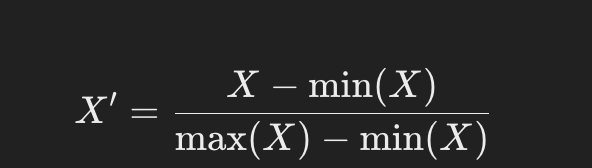

In [ ]:
# from sklearn.preprocessing import MinMaxScaler

# scaler = MinMaxScaler()
# X_scaled = scaler.fit_transform(X)


#Standardization (Z-Score Normalization)
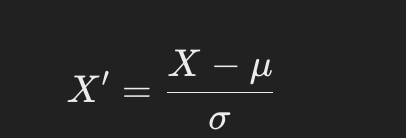

In [ ]:
# from sklearn.preprocessing import StandardScaler

# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)


In [ ]:
from sklearn.preprocessing import StandardScaler


# Standardize only the highly correlated numeric features
scaler = StandardScaler()
df_encoded[highly_correlated_numerical[1:]] = scaler.fit_transform(df_encoded[highly_correlated_numerical[1:]])
print(len(df_encoded))
df_encoded.head()

1460


,SalePrice,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,...,Neighborhood_23,Neighborhood_24,CentralAir_0,CentralAir_1,Foundation_0,Foundation_1,Foundation_2,Foundation_3,Foundation_4,Foundation_5
0,208500,0.370333,0.311725,0.351000,-0.459303,-0.793434,0.789741,0.912210,1.050994,0.878668,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,181500,-0.482512,0.311725,-0.060731,0.466465,0.257140,0.789741,-0.318683,0.156734,-0.429577,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,223500,0.515013,0.311725,0.631726,-0.313369,-0.627826,0.789741,-0.318683,0.984752,0.830215,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,140000,0.383659,1.650307,0.790804,-0.687324,-0.521734,-1.026041,0.296763,-1.863632,-0.720298,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
4,250000,1.299326,1.650307,1.698485,0.199680,-0.045611,0.789741,1.527656,0.951632,0.733308,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
